# **Megaline Telecom — Análise Estatística de Dados**

**Projeto de análise de dados | Python · Pandas · NumPy · Matplotlib · Seaborn · SciPy**

## **Introdução**

A Megaline oferece dois planos pré-pagos, **Surf** e **Ultimate**, e deseja compreender qual deles gera maior receita média. A análise utiliza dados de 500 clientes durante 2018, incluindo informações cadastrais, chamadas, mensagens de texto e sessões de internet.

O objetivo é transformar os registros operacionais em uma base mensal por cliente, calcular a receita conforme as regras comerciais de cada plano e investigar padrões de consumo. Em seguida, serão aplicados testes estatísticos para avaliar se existem diferenças nas receitas médias entre os planos e entre clientes da região NY-NJ e das demais regiões.

## **Etapas da análise**

1. Carregar e compreender as cinco bases de dados.
2. Preparar os dados, corrigindo tipos e aplicando as regras de arredondamento.
3. Agregar o consumo mensal por cliente e calcular a receita.
4. Analisar o comportamento dos clientes com estatística descritiva e visualizações.
5. Testar as hipóteses estatísticas e apresentar conclusões para o negócio.

**Critério de cobrança:** cada chamada é arredondada individualmente para cima; o uso mensal de internet é somado em MB e convertido para GB, com arredondamento para cima do total mensal. Um GB corresponde a 1.024 MB.

# **1. Inicialização e carregamento dos dados**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

### **1.1 Upload dos arquivos**

Faça o upload dos cinco arquivos CSV fornecidos pelo curso. Os nomes esperados estão listados abaixo.

In [3]:
# No Google Colab, verifica se os arquivos já existem ou solicita o upload.
import os
from google.colab import files

required_files = [
    "megaline_calls.csv",
    "megaline_internet.csv",
    "megaline_messages.csv",
    "megaline_plans.csv",
    "megaline_users.csv"
]

# Verifica se todos os arquivos necessários já estão no diretório atual
existing_files = [name for name in required_files if os.path.exists(name)]

if len(existing_files) < len(required_files):
    print("Alguns arquivos não foram encontrados no ambiente. Por favor, faça o upload:")
    uploaded = files.upload()
    # Caso os arquivos tenham sido carregados com o sufixo ' (1)', renomeia ou avisa
    missing_files = [name for name in required_files if name not in uploaded and not os.path.exists(name)]
    if missing_files:
        raise FileNotFoundError(f"Arquivos não encontrados no upload: {missing_files}")

calls = pd.read_csv("megaline_calls.csv")
internet = pd.read_csv("megaline_internet.csv")
messages = pd.read_csv("megaline_messages.csv")
plans = pd.read_csv("megaline_plans.csv")
users = pd.read_csv("megaline_users.csv")

print("Arquivos carregados com sucesso.")

Arquivos carregados com sucesso.


### **1.2 Visão geral das tabelas**

In [4]:
datasets = {
    "Chamadas": calls,
    "Internet": internet,
    "Mensagens": messages,
    "Planos": plans,
    "Usuários": users
}

for name, data in datasets.items():
    print(f"\n{name}: {data.shape[0]:,} linhas e {data.shape[1]} colunas")
    display(data.head(3))
    data.info()


Chamadas: 137,735 linhas e 4 colunas


,id,user_id,call_date,duration
0,1000_93,1000,2018-12-27,8.52
1,1000_145,1000,2018-12-27,13.66
2,1000_247,1000,2018-12-27,14.48


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 137735 entries, 0 to 137734
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   id         137735 non-null  object 
 1   user_id    137735 non-null  int64  
 2   call_date  137735 non-null  object 
 3   duration   137735 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 4.2+ MB

Internet: 104,825 linhas e 4 colunas


,id,user_id,session_date,mb_used
0,1000_13,1000,2018-12-29,89.86
1,1000_204,1000,2018-12-31,0.00
2,1000_379,1000,2018-12-28,660.40


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 104825 entries, 0 to 104824
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            104825 non-null  object 
 1   user_id       104825 non-null  int64  
 2   session_date  104825 non-null  object 
 3   mb_used       104825 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.2+ MB

Mensagens: 76,051 linhas e 3 colunas


,id,user_id,message_date
0,1000_125,1000,2018-12-27
1,1000_160,1000,2018-12-31
2,1000_223,1000,2018-12-31


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76051 entries, 0 to 76050
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id            76051 non-null  object
 1   user_id       76051 non-null  int64 
 2   message_date  76051 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.7+ MB

Planos: 2 linhas e 8 colunas


,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   messages_included      2 non-null      int64  
 1   mb_per_month_included  2 non-null      int64  
 2   minutes_included       2 non-null      int64  
 3   usd_monthly_pay        2 non-null      int64  
 4   usd_per_gb             2 non-null      int64  
 5   usd_per_message        2 non-null      float64
 6   usd_per_minute         2 non-null      float64
 7   plan_name              2 non-null      object 
dtypes: float64(2), int64(5), object(1)
memory usage: 260.0+ bytes

Usuários: 500 linhas e 8 colunas


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaN
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaN
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     500 non-null    int64 
 1   first_name  500 non-null    object
 2   last_name   500 non-null    object
 3   age         500 non-null    int64 
 4   city        500 non-null    object
 5   reg_date    500 non-null    object
 6   plan        500 non-null    object
 7   churn_date  34 non-null     object
dtypes: int64(2), object(6)
memory usage: 31.4+ KB


**Leitura inicial:** as tabelas possuem granularidades diferentes. Chamadas, mensagens e sessões de internet registram eventos individuais; `users` contém uma linha por cliente; e `plans` descreve as condições comerciais. Para calcular a receita, será necessário agregar os eventos por cliente e mês e, depois, relacioná-los ao plano contratado.

# **2. Preparação e qualidade dos dados**

### **2.1 Valores ausentes e registros duplicados**

In [5]:
print("VALORES AUSENTES")
display(pd.DataFrame({
    name: data.isna().sum()
    for name, data in datasets.items()
}).fillna(0).astype(int))

print("\nREGISTROS DUPLICADOS")
for name, data in datasets.items():
    print(f"{name}: {data.duplicated().sum():,}")

VALORES AUSENTES


,Chamadas,Internet,Mensagens,Planos,Usuários
age,0,0,0,0,0
call_date,0,0,0,0,0
churn_date,0,0,0,0,466
city,0,0,0,0,0
duration,0,0,0,0,0
first_name,0,0,0,0,0
id,0,0,0,0,0
last_name,0,0,0,0,0
mb_per_month_included,0,0,0,0,0
mb_used,0,0,0,0,0



REGISTROS DUPLICADOS
Chamadas: 0
Internet: 0
Mensagens: 0
Planos: 0
Usuários: 0


A ausência de `churn_date` na tabela de usuários indica que o cliente ainda utilizava o serviço no momento da extração dos dados. Portanto, esses valores não devem ser preenchidos artificialmente. Nas tabelas de eventos e planos, a inspeção de valores ausentes orienta a validação antes das agregações.

### **2.2 Conversão dos tipos de dados**

In [6]:
date_columns = {
    "Chamadas": ["call_date"],
    "Mensagens": ["message_date"],
    "Internet": ["session_date"],
    "Usuários": ["reg_date", "churn_date"]
}

for table_name, columns in date_columns.items():
    table = datasets[table_name]
    for column in columns:
        table[column] = pd.to_datetime(table[column], errors="coerce")

print("Tipos de dados após a conversão:")
for name, data in datasets.items():
    print(f"\n{name}")
    display(data.dtypes.to_frame("dtype"))

Tipos de dados após a conversão:

Chamadas


,dtype
id,object
user_id,int64
call_date,datetime64[ns]
duration,float64



Internet


,dtype
id,object
user_id,int64
session_date,datetime64[ns]
mb_used,float64



Mensagens


,dtype
id,object
user_id,int64
message_date,datetime64[ns]



Planos


,dtype
messages_included,int64
mb_per_month_included,int64
minutes_included,int64
usd_monthly_pay,int64
usd_per_gb,int64
usd_per_message,float64
usd_per_minute,float64
plan_name,object



Usuários


,dtype
user_id,int64
first_name,object
last_name,object
age,int64
city,object
reg_date,datetime64[ns]
plan,object
churn_date,datetime64[ns]


### **2.3 Regras de arredondamento e validações**

In [7]:
# Cada chamada é arredondada individualmente para o próximo minuto inteiro.
calls["duration"] = np.ceil(calls["duration"])

# Identificação de registros com duração ou consumo igual a zero.
zero_duration_calls = (calls["duration"] == 0).sum()
zero_data_sessions = (internet["mb_used"] == 0).sum()

print(f"Chamadas com duração zero: {zero_duration_calls:,}")
print(f"Sessões de internet com consumo zero: {zero_data_sessions:,}")

# Padronização de campos textuais usados nas junções e análises.
users["plan"] = users["plan"].str.strip().str.lower()
users["city"] = users["city"].str.strip()
plans["plan_name"] = plans["plan_name"].str.strip().str.lower()

print("\nPlanos encontrados nos usuários:", sorted(users["plan"].unique()))
print("Planos cadastrados na tabela de planos:", sorted(plans["plan_name"].unique()))

Chamadas com duração zero: 26,834
Sessões de internet com consumo zero: 13,747

Planos encontrados nos usuários: ['surf', 'ultimate']
Planos cadastrados na tabela de planos: ['surf', 'ultimate']


A duração das chamadas foi arredondada individualmente para cima, conforme a regra comercial. As sessões com duração zero permanecem na base: elas podem representar chamadas não tarifadas, mas continuam fazendo parte dos registros originais. O consumo de internet não é arredondado por sessão; o arredondamento será aplicado somente após a soma mensal por cliente.

### **2.4 Verificação das tabelas de planos e usuários**

In [8]:
display(plans)
display(users.head())

print(f"Quantidade de usuários: {users['user_id'].nunique():,}")
print(f"IDs de usuários duplicados: {users['user_id'].duplicated().sum():,}")
print(f"IDs de planos duplicados: {plans['plan_name'].duplicated().sum():,}")

,messages_included,mb_per_month_included,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute,plan_name
0,50,15360,500,20,10,0.03,0.03,surf
1,1000,30720,3000,70,7,0.01,0.01,ultimate


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,1000,Anamaria,Bauer,45,"Atlanta-Sandy Springs-Roswell, GA MSA",2018-12-24,ultimate,NaT
1,1001,Mickey,Wilkerson,28,"Seattle-Tacoma-Bellevue, WA MSA",2018-08-13,surf,NaT
2,1002,Carlee,Hoffman,36,"Las Vegas-Henderson-Paradise, NV MSA",2018-10-21,surf,NaT
3,1003,Reynaldo,Jenkins,52,"Tulsa, OK MSA",2018-01-28,surf,NaT
4,1004,Leonila,Thompson,40,"Seattle-Tacoma-Bellevue, WA MSA",2018-05-23,surf,NaT


Quantidade de usuários: 500
IDs de usuários duplicados: 0
IDs de planos duplicados: 0


A tabela de planos contém os limites incluídos e os preços cobrados por excedentes. A tabela de usuários associa cada cliente ao plano e à cidade. Essas informações serão utilizadas para calcular a receita mensal e formar os grupos da análise regional.

# **3. Agregação do consumo mensal por cliente**

A unidade de análise desta etapa será a combinação **cliente-mês**. Os registros de chamadas, mensagens e internet serão agregados separadamente e unidos por `user_id` e mês. Uma junção externa (`outer`) preserva meses em que o cliente utilizou apenas um ou dois dos serviços.

In [9]:
calls["month"] = calls["call_date"].dt.month
messages["month"] = messages["message_date"].dt.month
internet["month"] = internet["session_date"].dt.month

calls_monthly = (
    calls.groupby(["user_id", "month"])
    .agg(
        num_calls=("id", "count"),
        total_minutes=("duration", "sum")
    )
    .reset_index()
)

messages_monthly = (
    messages.groupby(["user_id", "month"])
    .agg(num_messages=("id", "count"))
    .reset_index()
)

internet_monthly = (
    internet.groupby(["user_id", "month"])
    .agg(mb_used=("mb_used", "sum"))
    .reset_index()
)

# Converter o total mensal de MB para GB e arredondar para cima.
internet_monthly["gb_used"] = np.ceil(
    internet_monthly["mb_used"] / 1024
).astype(int)

print("Agregação mensal concluída.")
display(calls_monthly.head())
display(messages_monthly.head())
display(internet_monthly.head())

Agregação mensal concluída.


,user_id,month,num_calls,total_minutes
0,1000,12,16,124.00
1,1001,8,27,182.00
2,1001,9,49,315.00
3,1001,10,65,393.00
4,1001,11,64,426.00


,user_id,month,num_messages
0,1000,12,11
1,1001,8,30
2,1001,9,44
3,1001,10,53
4,1001,11,36


,user_id,month,mb_used,gb_used
0,1000,12,"1,901.47",2
1,1001,8,"6,919.15",7
2,1001,9,"13,314.82",14
3,1001,10,"22,330.49",22
4,1001,11,"18,504.30",19


### **3.1 Consolidação das métricas**

In [10]:
df_monthly = (
    calls_monthly
    .merge(messages_monthly, on=["user_id", "month"], how="outer")
    .merge(internet_monthly, on=["user_id", "month"], how="outer")
)

usage_columns = ["num_calls", "total_minutes", "num_messages", "mb_used", "gb_used"]
df_monthly[usage_columns] = df_monthly[usage_columns].fillna(0)

integer_columns = ["num_calls", "total_minutes", "num_messages", "gb_used"]
df_monthly[integer_columns] = df_monthly[integer_columns].astype(int)

df_monthly = df_monthly.merge(
    users[["user_id", "plan", "city"]],
    on="user_id",
    how="left",
    validate="many_to_one"
)

df_monthly = df_monthly.sort_values(["user_id", "month"]).reset_index(drop=True)

print(f"Registros cliente-mês: {len(df_monthly):,}")
print(f"Clientes representados: {df_monthly['user_id'].nunique():,}")
display(df_monthly.head())

Registros cliente-mês: 2,293
Clientes representados: 490


,user_id,month,num_calls,total_minutes,num_messages,mb_used,gb_used,plan,city
0,1000,12,16,124,11,"1,901.47",2,ultimate,"Atlanta-Sandy Springs-Roswell, GA MSA"
1,1001,8,27,182,30,"6,919.15",7,surf,"Seattle-Tacoma-Bellevue, WA MSA"
2,1001,9,49,315,44,"13,314.82",14,surf,"Seattle-Tacoma-Bellevue, WA MSA"
3,1001,10,65,393,53,"22,330.49",22,surf,"Seattle-Tacoma-Bellevue, WA MSA"
4,1001,11,64,426,36,"18,504.30",19,surf,"Seattle-Tacoma-Bellevue, WA MSA"


Os valores ausentes nas métricas de uso foram substituídos por zero somente após a agregação e a junção. Nesse contexto, a ausência de um registro de serviço naquele mês significa que não houve uso registrado daquele serviço. A informação de plano e cidade foi adicionada a partir da tabela de usuários.

# **4. Cálculo da receita mensal**

Para cada registro cliente-mês, a receita é a soma da mensalidade fixa com os valores de excedentes. Os limites de internet da tabela de planos estão em MB; a comparação será feita em GB, usando 1.024 MB por GB.

In [11]:
plans_for_merge = plans.rename(columns={"plan_name": "plan"}).copy()
plans_for_merge["gb_per_month_included"] = (
    plans_for_merge["mb_per_month_included"] / 1024
)

df_monthly = df_monthly.merge(
    plans_for_merge,
    on="plan",
    how="left",
    validate="many_to_one"
)

df_monthly["extra_minutes"] = (
    df_monthly["total_minutes"] - df_monthly["minutes_included"]
).clip(lower=0)

df_monthly["extra_messages"] = (
    df_monthly["num_messages"] - df_monthly["messages_included"]
).clip(lower=0)

df_monthly["extra_gb"] = (
    df_monthly["gb_used"] - df_monthly["gb_per_month_included"]
).clip(lower=0)

df_monthly["revenue_minutes"] = (
    df_monthly["extra_minutes"] * df_monthly["usd_per_minute"]
)
df_monthly["revenue_messages"] = (
    df_monthly["extra_messages"] * df_monthly["usd_per_message"]
)
df_monthly["revenue_internet"] = (
    df_monthly["extra_gb"] * df_monthly["usd_per_gb"]
)

df_monthly["revenue"] = (
    df_monthly["usd_monthly_pay"]
    + df_monthly["revenue_minutes"]
    + df_monthly["revenue_messages"]
    + df_monthly["revenue_internet"]
)

display(df_monthly[
    ["user_id", "month", "plan", "total_minutes", "num_messages",
     "gb_used", "revenue_minutes", "revenue_messages",
     "revenue_internet", "revenue"]
].head(10))

,user_id,month,plan,total_minutes,num_messages,gb_used,revenue_minutes,revenue_messages,revenue_internet,revenue
0,1000,12,ultimate,124,11,2,0.00,0.00,0.00,70.00
1,1001,8,surf,182,30,7,0.00,0.00,0.00,20.00
2,1001,9,surf,315,44,14,0.00,0.00,0.00,20.00
3,1001,10,surf,393,53,22,0.00,0.09,70.00,90.09
4,1001,11,surf,426,36,19,0.00,0.00,40.00,60.00
5,1001,12,surf,412,44,19,0.00,0.00,40.00,60.00
6,1002,10,surf,59,15,7,0.00,0.00,0.00,20.00
7,1002,11,surf,386,32,19,0.00,0.00,40.00,60.00
8,1002,12,surf,384,41,15,0.00,0.00,0.00,20.00
9,1003,12,surf,1104,50,27,18.12,0.00,120.00,158.12


A receita mensal foi calculada respeitando os limites de cada plano. Quando o consumo fica abaixo do pacote, o excedente correspondente é zero e o cliente paga apenas a mensalidade. Quando ultrapassa o limite, somente a quantidade excedente é tarifada.

# **5. Análise exploratória do comportamento dos clientes**

### **5.1 Estatísticas descritivas por plano**

In [12]:
usage_metrics = ["total_minutes", "num_messages", "gb_used", "revenue"]

summary = df_monthly.groupby("plan")[usage_metrics].agg(
    ["count", "mean", "median", "var", "std", "min", "max"]
)
display(summary)

total_minutes                                          num_messages  \
                 count   mean median       var    std min   max        count   
plan                                                                           
surf              1573 428.75 425.00 54,968.28 234.45   0  1510         1573   
ultimate           720 430.45 424.00 57,844.46 240.51   0  1369          720   

                       ... gb_used         revenue                        \
          mean median  ...     std min max   count  mean median      var   
plan                   ...                                                 
surf     31.16  24.00  ...    7.85   0  70    1573 60.71  40.36 3,067.84   
ultimate 37.55  30.00  ...    7.67   0  46     720 72.31  70.00   129.85   

                             
           std   min    max  
plan                         
surf     55.39 20.00 590.37  
ultimate 11.40 70.00 182.00  

[2 rows x 28 columns]

As estatísticas descritivas permitem comparar o consumo típico e sua dispersão. A média é sensível a valores extremos; por isso, também são apresentadas mediana, variância e desvio padrão. As observações correspondem a registros cliente-mês, não a clientes únicos.

### **5.2 Distribuição do consumo mensal**

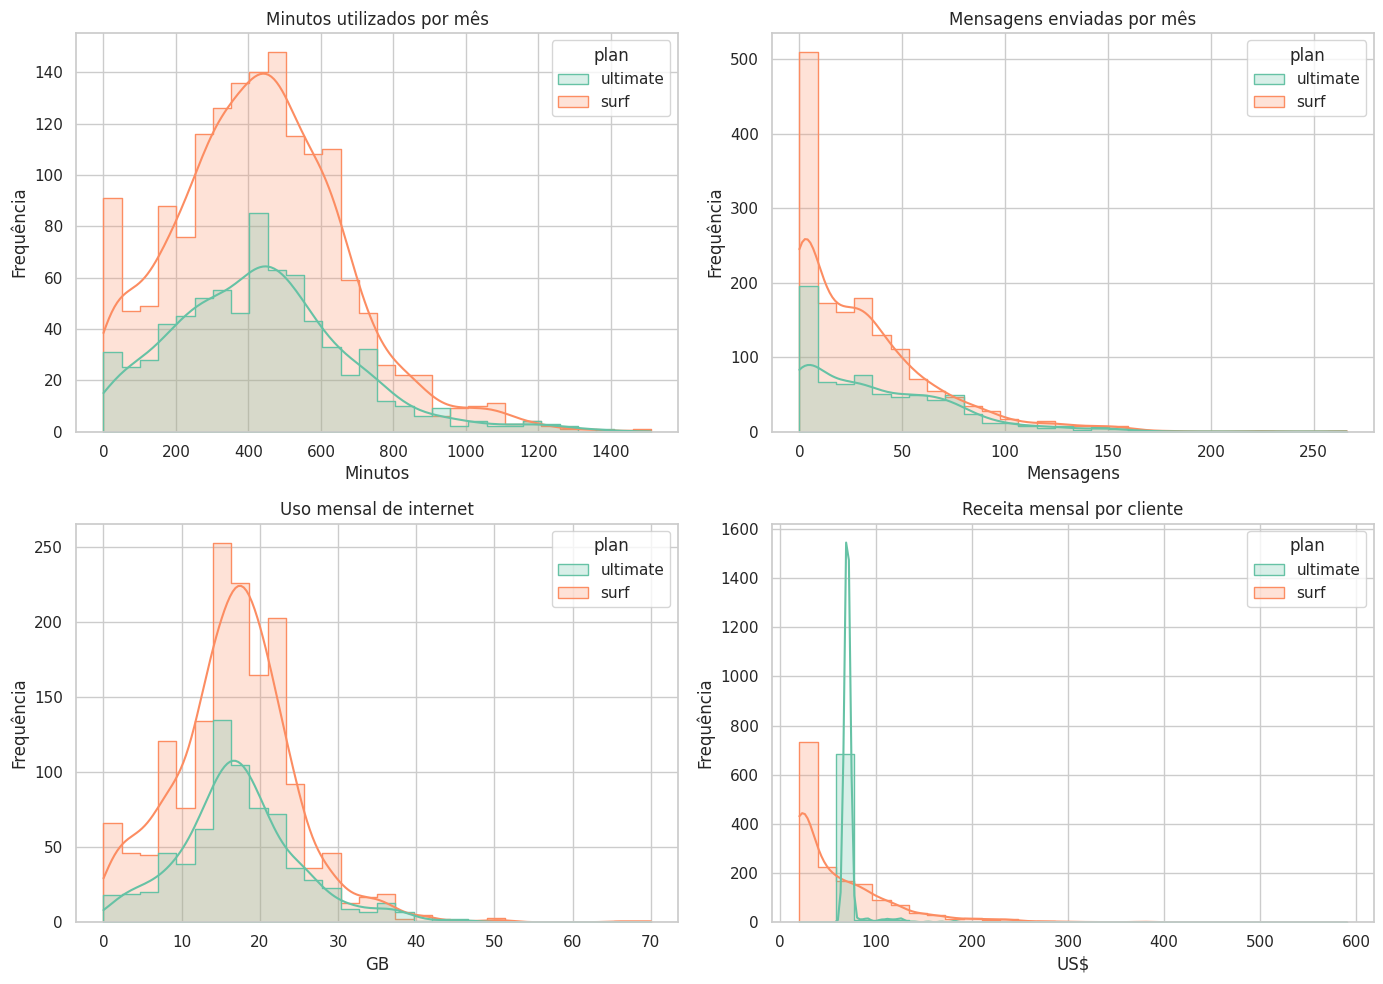

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_specs = [
    ("total_minutes", "Minutos utilizados por mês", "Minutos"),
    ("num_messages", "Mensagens enviadas por mês", "Mensagens"),
    ("gb_used", "Uso mensal de internet", "GB"),
    ("revenue", "Receita mensal por cliente", "US$")
]

for ax, (column, title, xlabel) in zip(axes.flat, plot_specs):
    sns.histplot(
        data=df_monthly, x=column, hue="plan",
        bins=30, kde=True, stat="count",
        common_norm=False, element="step", ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Frequência")

plt.tight_layout()
plt.show()

Os histogramas permitem observar a forma das distribuições e comparar os planos. A concentração de observações, a assimetria e a presença de valores extremos ajudam a explicar por que média e mediana podem diferir. A interpretação deve considerar também os limites incluídos em cada plano.

### **5.3 Consumo mensal por plano e mês**

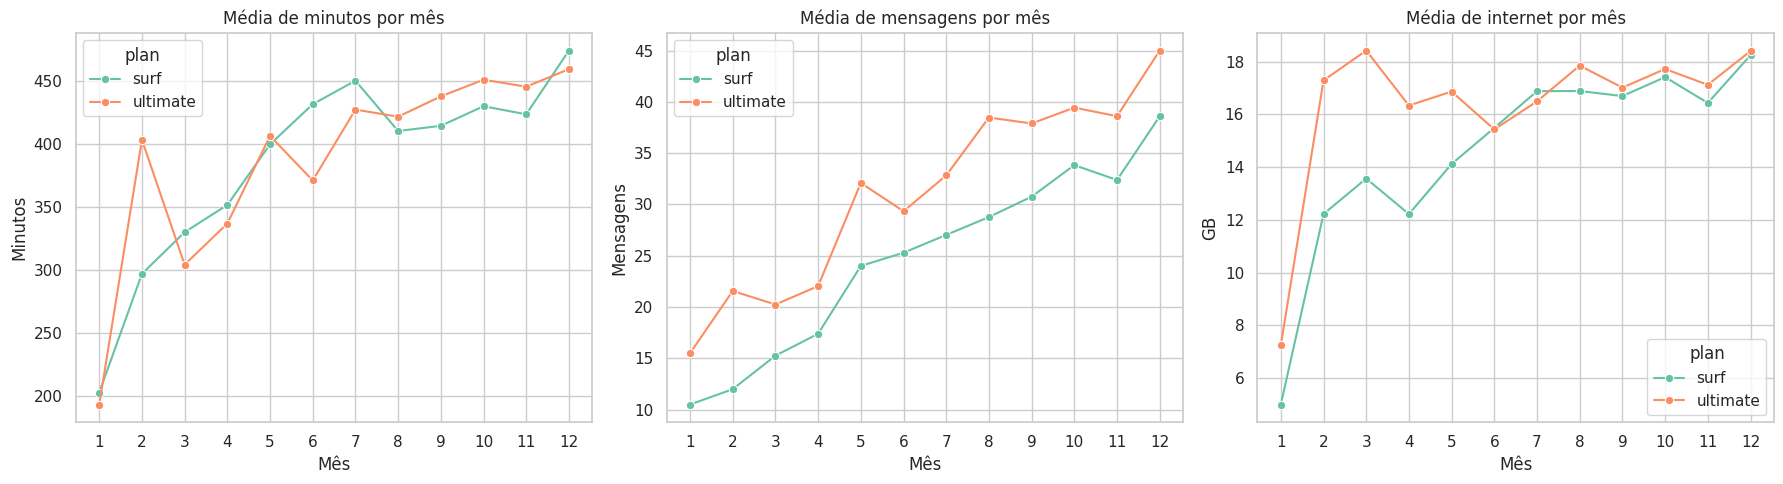

In [14]:
monthly_means = (
    df_monthly.groupby(["month", "plan"])[
        ["total_minutes", "num_messages", "gb_used"]
    ]
    .mean()
    .reset_index()
)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = [
    ("total_minutes", "Média de minutos por mês", "Minutos"),
    ("num_messages", "Média de mensagens por mês", "Mensagens"),
    ("gb_used", "Média de internet por mês", "GB")
]

for ax, (column, title, ylabel) in zip(axes, metrics):
    sns.lineplot(
        data=monthly_means, x="month", y=column,
        hue="plan", marker="o", ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Mês")
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(1, 13))

plt.tight_layout()
plt.show()

### **5.4 Distribuição mensal por plano**

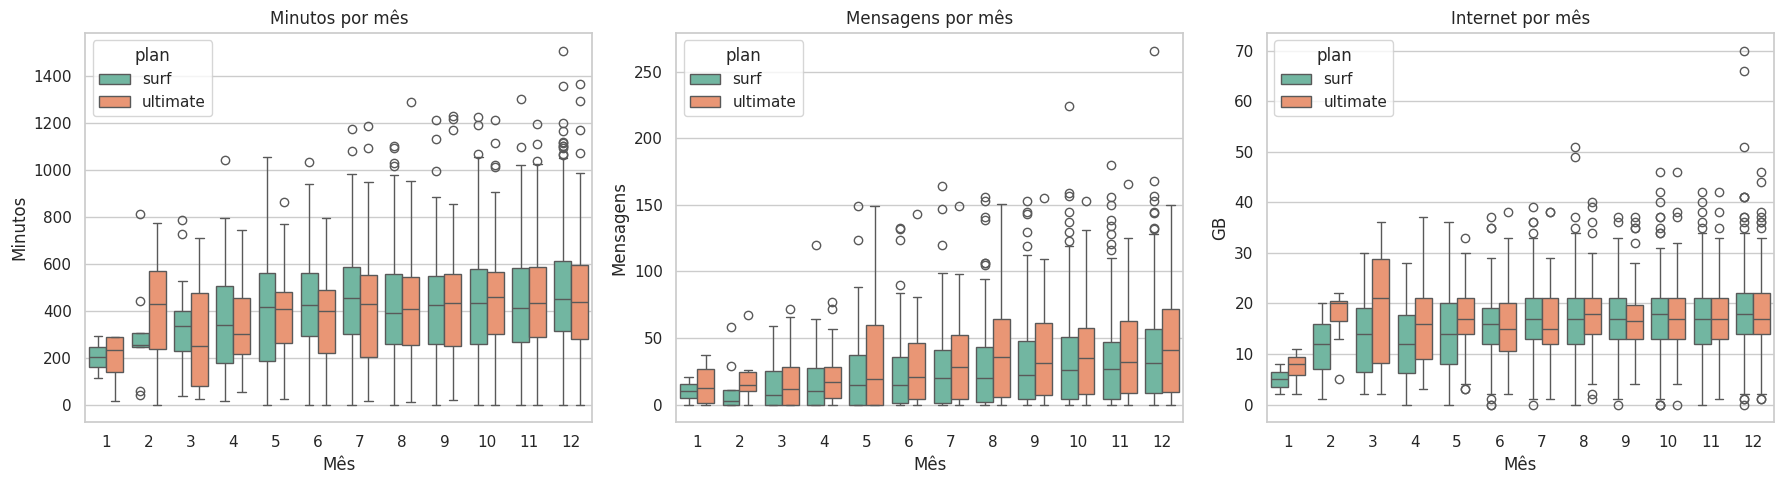

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
box_specs = [
    ("total_minutes", "Minutos por mês", "Minutos"),
    ("num_messages", "Mensagens por mês", "Mensagens"),
    ("gb_used", "Internet por mês", "GB")
]

for ax, (column, title, ylabel) in zip(axes, box_specs):
    sns.boxplot(data=df_monthly, x="month", y=column, hue="plan", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Mês")
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.show()

Os gráficos de caixa complementam os histogramas ao comparar mediana, dispersão interquartil e valores extremos por mês. Diferenças visuais não devem ser interpretadas automaticamente como diferenças estatisticamente significativas; essa avaliação será feita por meio dos testes de hipóteses.

### **5.5 Comparação da receita mensal**

,quantidade,media,mediana,desvio_padrao
plan,,,,
ultimate,720,72.31,70.00,11.40
surf,1573,60.71,40.36,55.39


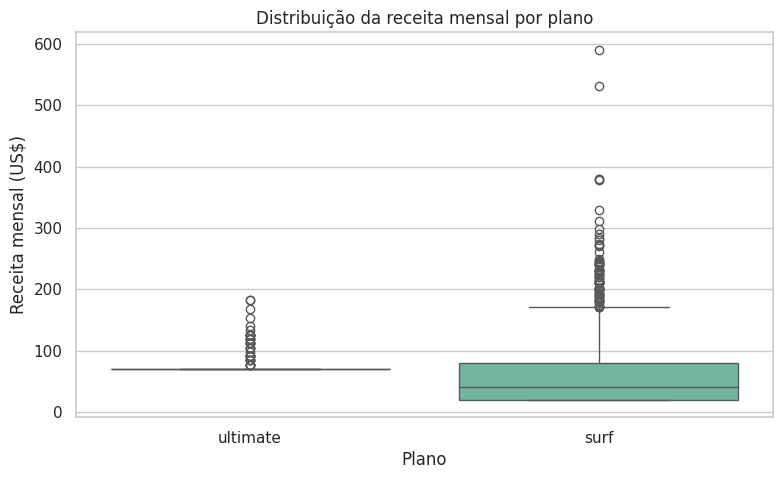

In [16]:
revenue_summary = df_monthly.groupby("plan")["revenue"].agg(
    quantidade="count",
    media="mean",
    mediana="median",
    desvio_padrao="std"
).sort_values("media", ascending=False)

display(revenue_summary)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_monthly, x="plan", y="revenue")
plt.title("Distribuição da receita mensal por plano")
plt.xlabel("Plano")
plt.ylabel("Receita mensal (US$)")
plt.show()

A comparação da receita deve considerar tanto o nível médio quanto a variabilidade. Um plano pode gerar receita média mais alta, mas também apresentar maior dispersão entre os meses-clientes. A decisão comercial deve considerar o resultado estatístico e a previsibilidade da receita.

# **6. Testes de hipóteses estatísticas**

Os testes utilizam nível de significância **α = 0,05**. Como as amostras são independentes e não se deve presumir igualdade das variâncias, será utilizado o teste t de Welch (`ttest_ind` com `equal_var=False`).

As hipóteses são bilaterais: o objetivo é verificar se as médias diferem, sem definir previamente qual grupo deve apresentar valor maior.

### **6.1 Receita média dos planos Surf e Ultimate**

- **H₀:** a receita média mensal dos registros cliente-mês dos planos Surf e Ultimate é igual.
- **H₁:** a receita média mensal dos registros cliente-mês dos planos Surf e Ultimate é diferente.

O teste t de Welch é adequado à comparação de médias de dois grupos independentes sem assumir variâncias iguais.

In [17]:
alpha = 0.05

surf_revenue = df_monthly.loc[df_monthly["plan"] == "surf", "revenue"]
ultimate_revenue = df_monthly.loc[df_monthly["plan"] == "ultimate", "revenue"]

plan_test = stats.ttest_ind(
    surf_revenue, ultimate_revenue,
    equal_var=False, alternative="two-sided"
)

print(f"Média Surf: US$ {surf_revenue.mean():.2f}")
print(f"Média Ultimate: US$ {ultimate_revenue.mean():.2f}")
print(f"Estatística t: {plan_test.statistic:.4f}")
print(f"Valor-p: {plan_test.pvalue:.8g}")

if plan_test.pvalue < alpha:
    print("Decisão: rejeitar H₀. Há evidência de diferença entre as receitas médias.")
else:
    print("Decisão: não rejeitar H₀. Não há evidência suficiente de diferença entre as receitas médias.")

Média Surf: US$ 60.71
Média Ultimate: US$ 72.31
Estatística t: -7.9521
Valor-p: 3.1703905e-15
Decisão: rejeitar H₀. Há evidência de diferença entre as receitas médias.


**Interpretação dos resultados:** a receita média observada foi de **US$ 60,71** no plano Surf e **US$ 72,31** no plano Ultimate. O teste de Welch resultou em valor-p de aproximadamente **3,17 × 10⁻¹⁵**, inferior a α = 0,05. Portanto, rejeitamos H₀ e concluímos que há evidência estatística de diferença entre as receitas médias dos dois planos. Nesta amostra, a média do Ultimate foi maior.

Essa conclusão se refere à receita média por registro cliente-mês. Ela não demonstra que o plano, isoladamente, cause a diferença, nem considera custos e rentabilidade.

### **6.2 Receita média da região NY-NJ e das demais regiões**

- **H₀:** a receita média mensal dos clientes da região NY-NJ é igual à receita média mensal dos clientes das demais regiões.
- **H₁:** as receitas médias mensais dos dois grupos são diferentes.

A região é identificada pela presença de `NY-NJ` no campo `city`, conforme a classificação geográfica da base. O teste t de Welch é aplicado a dois grupos independentes.

In [18]:
df_monthly["is_ny_nj"] = df_monthly["city"].str.contains(
    "NY-NJ", case=False, na=False
)

ny_nj_revenue = df_monthly.loc[df_monthly["is_ny_nj"], "revenue"]
other_regions_revenue = df_monthly.loc[~df_monthly["is_ny_nj"], "revenue"]

region_test = stats.ttest_ind(
    ny_nj_revenue, other_regions_revenue,
    equal_var=False, alternative="two-sided"
)

print(f"Observações NY-NJ: {len(ny_nj_revenue):,}")
print(f"Observações outras regiões: {len(other_regions_revenue):,}")
print(f"Média NY-NJ: US$ {ny_nj_revenue.mean():.2f}")
print(f"Média outras regiões: US$ {other_regions_revenue.mean():.2f}")
print(f"Estatística t: {region_test.statistic:.4f}")
print(f"Valor-p: {region_test.pvalue:.8f}")

if region_test.pvalue < alpha:
    print("Decisão: rejeitar H₀. Há evidência de diferença entre as receitas médias.")
else:
    print("Decisão: não rejeitar H₀. Não há evidência suficiente de diferença entre as receitas médias.")

Observações NY-NJ: 377
Observações outras regiões: 1,916
Média NY-NJ: US$ 59.92
Média outras regiões: US$ 65.22
Estatística t: -2.1309
Valor-p: 0.03352562
Decisão: rejeitar H₀. Há evidência de diferença entre as receitas médias.


**Interpretação dos resultados:** a receita média observada foi de **59,92** para os registros da região NY-NJ e de **65,22** para as demais regiões. O teste de Welch apresentou valor-p de aproximadamente **0,0335**, inferior a α = 0,05. Portanto, rejeitamos H₀ e encontramos evidência estatística de diferença entre as receitas médias dos grupos. Nesta amostra, a média das demais regiões foi maior.

A diferença observada não permite afirmar que a localização cause a variação de receita; características dos clientes, planos contratados e padrões de consumo também podem estar relacionados ao resultado.

# **7. Conclusão geral**

Este estudo analisou os dados de 500 clientes da Megaline durante 2018 para comparar o comportamento de uso e a receita dos planos Surf e Ultimate.

As cinco tabelas foram inspecionadas e preparadas. As datas foram convertidas para o tipo apropriado, a duração de cada chamada foi arredondada individualmente para cima e o tráfego de internet foi agregado por cliente e mês antes da conversão para GB e do arredondamento mensal. Em seguida, as informações de consumo foram consolidadas em uma base cliente-mês e combinadas às condições comerciais dos planos.

A receita mensal foi calculada pela soma da mensalidade fixa e das cobranças por excedentes de minutos, mensagens e internet. Na amostra analisada, a receita média por registro cliente-mês foi de **60,71 no Surf** e **72,31 no Ultimate**. O teste t de Welch apresentou valor-p de aproximadamente **3,17 × 10⁻¹⁵**; portanto, há evidência estatística de diferença entre as médias, com valor observado maior no plano Ultimate.

Na comparação regional, a receita média foi de **59,92 em NY-NJ** e **65,22 nas demais regiões**. O teste t de Welch apresentou valor-p de aproximadamente **0,0335**, indicando diferença estatisticamente significativa ao nível de 5%. Nesta amostra, a média das demais regiões foi maior.

Os resultados sugerem que o plano Ultimate gera maior receita média por registro cliente-mês, enquanto a região NY-NJ apresenta receita média inferior à das demais regiões. Para orientar a alocação do orçamento de publicidade, a empresa também deve considerar volume de clientes, variabilidade da receita, custos operacionais, aquisição e retenção. Receita não equivale a lucro, e os resultados desta análise não substituem uma avaliação de margem e retorno sobre investimento em marketing.

# **8. Limitações da análise**

- A base representa uma amostra de 500 clientes e o período observado é o ano de 2018; os resultados não devem ser automaticamente generalizados para outros períodos.
- As observações utilizadas nos testes são registros cliente-mês. Um mesmo cliente pode contribuir com mais de uma observação, portanto os registros mensais de um mesmo indivíduo não são necessariamente independentes. Essa dependência é uma limitação do teste t aplicado.
- O teste de diferença de médias não controla simultaneamente outras características dos clientes, como plano, cidade, idade ou padrão de uso.
- A receita não equivale a lucro: não foram considerados custos operacionais, custos de rede, aquisição ou retenção de clientes.

Essas limitações devem ser consideradas ao transformar os resultados estatísticos em recomendações de negócio.